# Demo II: hard constraints, routes to a symmetric model

*Part II of the lecture "AI for Science: putting physics into learning". This notebook
can be read and run on its own: it needs only `numpy`, `matplotlib` and `torch`, and
takes about a minute and a half on a laptop CPU.*

## The question

Demo I added physics to the **loss**: a soft constraint, satisfied approximately. Here
the physics is a **symmetry**, and it can be built into the **model itself**, so that it
holds exactly, for any weights, before any training. This is a **hard constraint**.

The example is the workhorse of atomistic machine learning: predict the energy $E$ of a
small cluster of identical atoms from their positions. Whatever the interaction,

$$E(\mathbf r_1, \dots, \mathbf r_N) \text{ is unchanged by translations, rotations, and permutations of the atoms.}$$

A network fed with the $3N$ raw coordinates does not know this: for it, a rotated
cluster is a completely new input.

## The experiment

Target: the energy of a 6-atom cluster, Lennard-Jones + Axilrod-Teller three-body term.
Five models, same training data:

| model | how the symmetry is handled |
|---|---|
| (a) MLP on raw coordinates | not at all |
| (b) same MLP + random rotations of the training data, 10 times more training steps | **soft** (augmentation) |
| (c) same MLP after **canonicalisation** (inertia frame + atom sorting) | **hard** |
| (d) atom-centred model on **invariant descriptors**, $E=\sum_i \varepsilon_\theta(G_i)$ | **hard** |
| (e) **equivariant graph network**: atoms exchange messages along interatomic vectors | **hard** |

(a), (b) and (c) use the **same network**; they differ only in what is done to the
coordinates before they enter it.

## What to look for

1. **Test 1**: trained in one orientation, tested on rotated copies, then on rotated
   and relabelled copies. Augmentation learns the rotations approximately, at a price in
   accuracy and training time, and knows nothing of the relabelling. The hard
   constraints handle both exactly.
2. **Test 2**: hard constraints need far less data.
3. **Test 3**: every route has a price. Canonicalisation makes the model discontinuous,
   descriptors lose information.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

torch.set_default_dtype(torch.float64)
torch.set_num_threads(4)
t_start = time.time()

BLUE, RED, GREEN, ORANGE, GREY = "#5073B8", "#B85050", "#50B873", "#EBA05A", "#888888"
PURPLE = "#9B6FB8"
COLORS = {"a": RED, "b": ORANGE, "c": GREEN, "d": BLUE, "e": PURPLE}
LABELS = {"a": "(a) raw coordinates", "b": "(b) augmentation (soft)",
          "c": "(c) canonicalisation (hard)", "d": "(d) invariant descriptors (hard)",
          "e": "(e) equivariant GNN (hard)"}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

os.makedirs("figures", exist_ok=True)      # each figure is also saved there as a PDF

N_ATOMS = 6

## The physics: Lennard-Jones + Axilrod-Teller

The "true" energy plays the role of an expensive quantum calculation. It is

$$E = \sum_{i<j} 4\left(r_{ij}^{-12} - r_{ij}^{-6}\right)
+ \nu \sum_{i<j<k} \frac{1 + 3\cos\gamma_i\cos\gamma_j\cos\gamma_k}{(r_{ij}\, r_{ik}\, r_{jk})^{3}}$$

in reduced units, with $\nu = 0.5$. The first sum is the Lennard-Jones pair interaction.
The second is the Axilrod-Teller term, which depends on the three angles $\gamma$ of each
triangle of atoms: it is there so that the energy is **not** a sum of pair terms, and the
models have something non-trivial to learn.

$E$ depends only on distances and angles, so it has the three symmetries by construction.

The cell also defines the tools to apply a symmetry operation $g$ to a batch of
configurations: a random proper rotation (from the QR decomposition of a Gaussian matrix)
and a random relabelling of the atoms. `rotate(X)`, `relabel(X)` and
`rotate_permute(X)` return $gX$, a different array of numbers describing **the same
physical cluster**, with the same energy.

In [2]:
def energy(X, nu=0.5):
    """X: (B, N, 3) -> (B,) energy, LJ pairs (eps=sigma=1) + Axilrod-Teller triplets."""
    diff = X[:, :, None, :] - X[:, None, :, :]
    r = torch.sqrt((diff**2).sum(-1) + torch.eye(N_ATOMS))       # avoid sqrt(0) on diagonal
    iu = torch.triu_indices(N_ATOMS, N_ATOMS, 1)
    rp = r[:, iu[0], iu[1]]
    e_lj = (4 * (rp**-12 - rp**-6)).sum(-1)
    e_at = 0.0
    for i in range(N_ATOMS):
        for j in range(i + 1, N_ATOMS):
            for k in range(j + 1, N_ATOMS):
                rij, rik, rjk = r[:, i, j], r[:, i, k], r[:, j, k]
                ci = (rij**2 + rik**2 - rjk**2) / (2 * rij * rik)
                cj = (rij**2 + rjk**2 - rik**2) / (2 * rij * rjk)
                ck = (rik**2 + rjk**2 - rij**2) / (2 * rik * rjk)
                e_at = e_at + nu * (1 + 3 * ci * cj * ck) / (rij * rik * rjk) ** 3
    return e_lj + e_at


def random_rotations(B, gen):
    q, r = torch.linalg.qr(torch.randn(B, 3, 3, generator=gen))
    q = q * torch.sign(torch.diagonal(r, dim1=-2, dim2=-1))[:, None, :]
    det = torch.linalg.det(q)
    q[:, :, 0] *= det[:, None]                                    # proper rotations
    return q


def random_permutations(B, gen):
    return torch.argsort(torch.rand(B, N_ATOMS, generator=gen), dim=1)


def rotate(X, gen):
    return X @ random_rotations(len(X), gen).transpose(1, 2)


def relabel(X, gen):
    P = random_permutations(len(X), gen)
    return torch.gather(X, 1, P[:, :, None].expand(-1, -1, 3))


def rotate_permute(X, gen):
    R = random_rotations(len(X), gen)
    P = random_permutations(len(X), gen)
    Xp = torch.gather(X, 1, P[:, :, None].expand(-1, -1, 3))
    return Xp @ R.transpose(1, 2)

## Canonicalisation: inertia frame, sign convention, atom ordering

First hard route, used by model (c): before the network sees a configuration, bring it
to a **standard pose**, chosen by a rule that depends only on the cluster itself.
All the symmetric copies of a configuration then give the same input vector, hence
the same output. One convention is needed per symmetry:

| symmetry | convention in `canonicalise` |
|---|---|
| translation | put the centre of mass at the origin |
| rotation | use the principal axes of the cluster (eigenvectors of $\sum_i \mathbf r_i \mathbf r_i^T$) as the frame |
| sign of each axis | an eigenvector is defined up to a sign: choose it so that $\sum_i y_i^3 > 0$ along each axis |
| permutation | sort the atoms by their projection on a fixed direction `U_SORT` of that frame |

Each convention is ambiguous for some configurations: two equal moments of inertia, a
vanishing third moment, two atoms with the same projection. Keep this in mind for Test 3.
The helper `best_direction` picks the sorting direction that separates the atoms of the
reference cluster best, to stay as far as possible from that last ambiguity.

In [3]:
U_SORT = torch.tensor([1.0, 0.6, 0.3]) / np.sqrt(1 + 0.36 + 0.09)   # sorting direction (re-chosen below)
_dirs = torch.nn.functional.normalize(torch.randn(500, 3, generator=torch.Generator().manual_seed(3)), dim=1)


def best_direction(Y):
    """Direction (in the canonical frame) along which the atoms are best separated."""
    gaps = torch.diff(torch.sort(Y @ _dirs.T, dim=0).values, dim=0).min(0).values
    return _dirs[torch.argmax(gaps)], gaps.max().item()


def canonicalise(X):
    Xc = X - X.mean(1, keepdim=True)
    cov = Xc.transpose(1, 2) @ Xc
    _, vecs = torch.linalg.eigh(cov)                    # principal axes, ascending
    Y = Xc @ vecs
    sign = torch.sign((Y**3).sum(1, keepdim=True))      # third moment fixes the sign of each axis
    Y = Y * sign
    order = torch.argsort(Y @ U_SORT, dim=1)            # permutation: sort atoms along U_SORT
    return torch.gather(Y, 1, order[:, :, None].expand(-1, -1, 3))

## Reference geometry and datasets

We pick a compact, non-symmetric reference cluster (so that canonicalisation is
well defined), then sample thermal-like perturbations around it: each atom is displaced
by Gaussian noise of standard deviation $0.03$ (in units of the Lennard-Jones diameter).
This mimics a small molecule vibrating around one structure.

`make_reference` is bookkeeping: it relaxes 400 random clusters a little and keeps the one
whose canonical pose is the most robust (well separated moments of inertia, third moments
and projections). It gives canonicalisation its **best case**.

Two datasets come out of this cell:

- a **training pool** of 4000 configurations, all in the **same orientation** and with
  the same atom order;
- a **test set** of 1000 other configurations, in three versions: `X_test0` as sampled,
  `X_test`, the same clusters **randomly rotated**, and `X_test_perm`, rotated **and
  relabelled**. The three versions have the same energies `E_test`.

In [4]:
def make_reference(n_candidates=400):
    """Among partially relaxed random clusters, keep the one whose canonical frame and atom
    ordering are the most robust to thermal noise: well-separated moments of inertia,
    large third moments (sign convention) and well-separated atom projections (ordering)."""
    X = torch.cat([(torch.rand(1, N_ATOMS, 3, generator=torch.Generator().manual_seed(seed)) - 0.5) * 2.2
                   for seed in range(n_candidates)]).requires_grad_(True)
    for _ in range(60):                                  # partial relaxation only, all at once
        (grad,) = torch.autograd.grad(energy(X).sum(), X)
        with torch.no_grad():
            X -= 0.002 * grad.clamp(-50, 50)
    X = X.detach()
    best, best_score = None, 0.0
    for x in X:
        xc = x - x.mean(0)
        moments, vecs = torch.linalg.eigh(xc.T @ xc)
        gaps_m = (moments[1:] - moments[:-1]) / moments.mean()
        third = ((xc @ vecs) ** 3).sum(0).abs()
        u, gap = best_direction(canonicalise(x[None])[0])
        score = min(gap / 0.3, third.min().item() / 0.5, gaps_m.min().item() / 0.3)
        if torch.cdist(x, x).max() < 2.8 and score > best_score:
            best, best_score, best_u = xc, score, u
            info = (gap, third.min().item(), gaps_m.min().item())
    print(f"reference: E = {energy(best[None]).item():.2f}, projection gap = {info[0]:.2f}, "
          f"min |third moment| = {info[1]:.2f}, min relative moment gap = {info[2]:.2f}")
    return best, best_u


X_ref, U_SORT = make_reference()


def sample(n, gen, sigma=0.03):
    X = X_ref + sigma * torch.randn(n, N_ATOMS, 3, generator=gen)
    return X, energy(X)


gen = torch.Generator().manual_seed(42)
X_pool, E_pool = sample(4000, gen)           # training pool, ONE orientation and atom order
X_test0, E_test = sample(1000, gen)          # test configurations ...
X_test = rotate(X_test0, gen)                # ... randomly rotated ...
X_test_perm = relabel(X_test, gen)           # ... and with the atoms relabelled
print(f"energy range: {E_pool.min():.2f} to {E_pool.max():.2f}")

reference: E = -5.80, projection gap = 0.33, min |third moment| = 0.37, min relative moment gap = 0.46
energy range: -6.12 to -0.61


Here is what the networks are given. Left: the reference cluster, in the pose used for
training (atoms closer than 1.6 are joined by a line, nearer atoms are drawn larger).
Right: **the same cluster** after a random rotation and a random relabelling of the atoms.
The colours follow the atoms, the numbers are their positions in the input array. The
energy is the same, the 18 input numbers are all different.

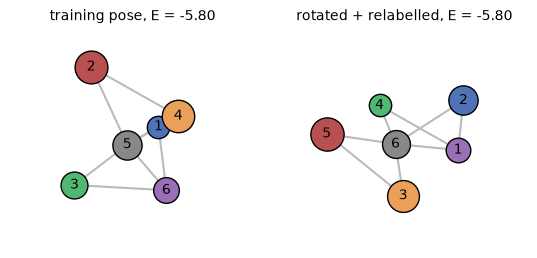

In [5]:
BOND = 1.6


def draw_cluster(ax, X, colors, title):
    X = X - X.mean(0)
    d = torch.cdist(X, X)
    for i in range(N_ATOMS):
        for j in range(i + 1, N_ATOMS):
            if d[i, j] < BOND:
                ax.plot(X[[i, j], 0], X[[i, j], 1], color="#BBBBBB", lw=1.5, zorder=-10)
    for i in range(N_ATOMS):
        z = X[i, 2].item()
        ax.scatter(X[i, 0], X[i, 1], s=420 + 160 * z, color=colors[i], edgecolor="k", zorder=z + 0.01)
        ax.text(X[i, 0], X[i, 1], str(i + 1), ha="center", va="center", fontsize=10, zorder=z + 0.02)
    ax.set_title(title, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-1.7, 1.7)
    ax.axis("off")


g = torch.Generator().manual_seed(3)
R, P = random_rotations(1, g)[0], random_permutations(1, g)[0]
X_rot = X_ref[P] @ R.T
atom_colors = np.array([BLUE, RED, GREEN, ORANGE, GREY, PURPLE])
fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.6))
draw_cluster(axes[0], X_ref, atom_colors, f"training pose, E = {energy(X_ref[None]).item():.2f}")
draw_cluster(axes[1], X_rot, atom_colors[P.numpy()], f"rotated + relabelled, E = {energy(X_rot[None]).item():.2f}")
fig.tight_layout()
fig.savefig("figures/fig_II_cluster.pdf")
plt.show()

## A short movie: what moves, and what the energy does

To get a feeling for the data, the next cell makes a small animation (use the play
button under the figure). It has two parts.

1. **The atoms move.** The cluster goes smoothly through six configurations of the
   training pool. The displacements are small (a few percent of the distance between
   neighbours), so each one is also drawn as a black arrow, **magnified 15 times**. The
   right panel shows the energy along the way: it changes a lot, because the
   Lennard-Jones repulsion is very steep when two atoms get closer.
2. **The whole cluster rotates.** Every one of the 18 coordinates changes, much more
   than in part 1, and the energy stays exactly constant.

This is the whole problem of the demo: the network must be sensitive to the small
motions of part 1 and blind to the large motion of part 2.

In [6]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

N_KEY, N_STEP, N_ROT, MAGNIFY = 6, 8, 24, 15
keys = torch.cat([X_ref[None], X_pool[:N_KEY], X_ref[None]])           # start and end at the reference
frames = []
for a, b in zip(keys[:-1], keys[1:]):                                   # smooth path between configurations
    for s in np.linspace(0, 1, N_STEP, endpoint=False):
        w = 0.5 - 0.5 * np.cos(np.pi * s)
        frames.append((1 - w) * a + w * b)
n_move = len(frames)
axis = torch.tensor([1.0, 1.0, 0.5], dtype=X_ref.dtype)
axis = axis / axis.norm()
K = torch.tensor([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]], dtype=X_ref.dtype)
for angle in np.linspace(0, 2 * np.pi, N_ROT):                          # rigid rotation about a tilted axis
    R = torch.eye(3, dtype=X_ref.dtype) + np.sin(angle) * K + (1 - np.cos(angle)) * K @ K
    frames.append(X_ref @ R.T)
frames = torch.stack(frames)
E_frames = energy(frames)

fig, (ax_c, ax_e) = plt.subplots(1, 2, figsize=(8, 3.2), dpi=72, gridspec_kw={"width_ratios": [1, 1.3]})
fig.subplots_adjust(left=0.02, right=0.97, bottom=0.17, top=0.9, wspace=0.25)
E_TOP = E_frames.max().item() + 0.2


def draw_frame(k):
    ax_c.cla()
    ax_e.cla()
    moving = k < n_move
    draw_cluster(ax_c, frames[k], atom_colors, "1. the atoms move" if moving else "2. the cluster rotates")
    if moving:
        d = MAGNIFY * (frames[k] - X_ref)
        for i in range(N_ATOMS):
            if d[i, :2].norm() > 0.03:
                ax_c.annotate("", xy=(X_ref[i, 0] + d[i, 0], X_ref[i, 1] + d[i, 1]), xytext=(X_ref[i, 0], X_ref[i, 1]),
                              arrowprops={"arrowstyle": "->", "color": "k", "lw": 2}, zorder=20)
    ax_e.axvspan(n_move, len(frames) - 1, color=GREY, alpha=0.15, lw=0)
    ax_e.plot(E_frames, color=GREY, lw=1)
    ax_e.plot(E_frames[:k + 1], color=BLUE, lw=2)
    ax_e.plot(k, E_frames[k], "o", color=BLUE, ms=7)
    ax_e.set_ylim(E_frames.min().item() - 0.1, E_TOP)
    ax_e.text(n_move / 2, E_TOP, "atoms move", ha="center", va="top", fontsize=9)
    ax_e.text((n_move + len(frames)) / 2, E_TOP, "rotation", ha="center", va="top", fontsize=9)
    ax_e.set_xlabel("frame")
    ax_e.set_ylabel("energy")
    ax_e.set_title(f"E = {E_frames[k]:.2f}", fontsize=10)


anim = FuncAnimation(fig, draw_frame, frames=len(frames), interval=120)
movie = HTML(anim.to_jshtml(default_mode="loop"))
plt.close(fig)
movie

## Invariant descriptors (Behler-Parrinello style symmetry functions)

Second hard route, used by model (d): do not give coordinates to the network at all.
Describe the **environment of each atom** $i$ by numbers that are invariant from the start:

- 12 **radial** functions, $G_i^{\mathrm{rad}}(s) = \sum_{j\neq i} e^{-6\,(r_{ij}-s)^2}$ for 12
  values of the shift $s$: a smooth histogram of the distances to the neighbours;
- 16 **angular** functions,
  $G_i^{\mathrm{ang}} = 2^{1-\zeta}\sum_{j \neq k} (1+\lambda\cos\theta_{jik})^{\zeta}\, e^{-\eta\,(r_{ij}^2+r_{ik}^2)}$
  for several $(\lambda, \zeta, \eta)$: a smooth histogram of the angles between pairs of
  neighbours.

Distances and angles do not change under rotations and translations, and the **sums**
over neighbours do not depend on their order. The total energy is then written as a sum
of atomic contributions computed by **one shared network**,
$E = \sum_i \varepsilon_\theta(G_i)$, which makes it invariant to permutations as well.
This is the architecture of Behler and Parrinello (2007), the first generation of
machine-learned interatomic potentials.

The price: 28 numbers per atom are a **summary** of the environment. Two different
environments can have nearly the same descriptors, and the model cannot tell them apart.

In [7]:
SHIFTS = torch.linspace(0.9, 2.8, 12)
N_DESC = 12 + 16


def descriptors(X):
    """(B, N, 3) -> (B, N, 28): radial + angular symmetry functions per atom."""
    diff = X[:, :, None, :] - X[:, None, :, :]
    r = torch.sqrt((diff**2).sum(-1) + 1e-12)
    mask = 1 - torch.eye(N_ATOMS)
    g_rad = (torch.exp(-6.0 * (r[..., None] - SHIFTS) ** 2) * mask[..., None]).sum(2)
    unit = diff / r[..., None]
    cos = torch.einsum("bijx,bikx->bijk", unit, unit)                 # angle j-i-k
    m3 = mask[:, :, None] * mask[:, None, :] * (1 - torch.eye(N_ATOMS))[None]
    r2 = r[:, :, :, None] ** 2 + r[:, :, None, :] ** 2
    g_ang = [((1 + lam * cos) ** zeta * torch.exp(-eta * r2) * m3).sum((2, 3)) * 2 ** (1 - zeta)
             for lam in (1, -1) for zeta in (1, 2, 4, 8) for eta in (0.3, 1.0)]
    return torch.cat([g_rad, torch.stack(g_ang, -1)], -1)

## Models (a) to (d)

These four use the same small network (2 hidden layers of 64 units) and the same training
procedure: 3000 Adam steps on mini-batches of 128 configurations, mean squared error on
the energy. The class `Model` only changes the **features** fed to the network:

- (a) and (b): the 18 raw coordinates;
- (c): the 18 coordinates after `canonicalise`;
- (d): the 28 descriptors of each atom, the network being applied to each atom and
  the outputs summed.

(b) is model (a) trained differently: at every step, each configuration of the batch is
replaced by a randomly **rotated** copy (same energy). This is **data augmentation**.
The symmetry is shown to the network through examples, not imposed: a soft constraint,
like the physics term of demo I. Learning a symmetry from examples is slow, so (b) is
given **10 times more training steps** than the other models (`AUG_FACTOR`).

Only rotations are augmented, which is what is done in practice. Augmenting over the
$6! = 720$ relabellings of the atoms as well does not work here: the network settles on
a constant prediction, even with a network 100 times larger and 40000 steps (try it:
replace `rotate` by `rotate_permute` in `train`).

## Model (e): an equivariant graph network

The fourth route of the lecture: keep the coordinates, and build the symmetry into
**every layer**. The cluster is a graph, each atom is a node and carries a feature
vector $h_i$ (the same for all atoms at the start, since they are identical). One layer
does three things:

1. **Messages.** For each pair, $m_{ij} = \phi_e(h_i, h_j, d_{ij})$, a small network
   of the two features and the **distance** $d_{ij}$. Distances do not change under
   rotations and translations.
2. **Vectors.** Each atom sums the unit vectors pointing to its neighbours, weighted by
   the messages: $\mathbf v_i = \sum_j \hat{\mathbf r}_{ij}\, W m_{ij}$ (4 vectors per
   atom). If the cluster is rotated, these vectors **rotate with it**: this is the
   equivariant part. Their scalar products $\mathbf v_i^a \cdot \mathbf v_i^b$ are
   invariant again, and they carry what distances alone miss: the **angles** between
   neighbours.
3. **Update.** $h_i \leftarrow h_i + \phi_h\big(h_i, \sum_j m_{ij}, \mathbf v_i^a\cdot\mathbf v_i^b\big)$.

The energy is $E = \sum_i \rho(h_i)$. Sums over neighbours and over atoms make the
model independent of the atom order; the layer is permutation-**equivariant** (relabel
the atoms and the $h_i$ are relabelled the same way), and the final sum is invariant.

Unlike (d), nothing is designed by hand: the networks $\phi_e$, $\phi_h$, $\rho$ are
unconstrained and learn which functions of distances and angles matter. The symmetry
comes from the way they are wired. The distance enters through 16 narrow Gaussians, a
smooth one-hot encoding. This model is a minimal version of the equivariant networks
used in practice (EGNN, NequIP, MACE); it is more than ten times slower per step than
the MLPs above.

In [8]:
def mlp(n_in, width=64):
    return torch.nn.Sequential(torch.nn.Linear(n_in, width), torch.nn.SiLU(),
                               torch.nn.Linear(width, width), torch.nn.SiLU(),
                               torch.nn.Linear(width, 1))


class EquivariantGNN(torch.nn.Module):
    """One message-passing layer with invariant features h_i and equivariant vectors v_i."""

    def __init__(self, width=32, n_vec=4):
        super().__init__()
        self.centres = torch.linspace(0.9, 3.0, 16)
        self.h0 = torch.nn.Parameter(torch.zeros(width))
        self.phi_e = torch.nn.Sequential(torch.nn.Linear(2 * width + 16, width), torch.nn.SiLU(),
                                         torch.nn.Linear(width, width), torch.nn.SiLU())
        self.to_vec = torch.nn.Linear(width, n_vec)
        self.phi_h = torch.nn.Sequential(torch.nn.Linear(2 * width + n_vec**2, width), torch.nn.SiLU(),
                                         torch.nn.Linear(width, width))
        self.rho = torch.nn.Sequential(torch.nn.Linear(width, width), torch.nn.SiLU(),
                                       torch.nn.Linear(width, 1))

    def forward(self, X):
        B, N, _ = X.shape
        diff = X[:, :, None, :] - X[:, None, :, :]                    # r_i - r_j, rotates with X
        d = torch.sqrt((diff**2).sum(-1) + torch.eye(N))             # distances, invariant
        unit = diff / d[..., None]
        d_enc = torch.exp(-40.0 * (d[..., None] - self.centres) ** 2)
        not_self = (1 - torch.eye(N))[None, :, :, None]
        h = self.h0.expand(B, N, -1)
        pairs = torch.cat([h[:, :, None].expand(-1, -1, N, -1), h[:, None].expand(-1, N, -1, -1), d_enc], -1)
        m = self.phi_e(pairs) * not_self                              # messages m_ij, invariant
        v = torch.einsum("bijx,bijc->bixc", unit, self.to_vec(m))     # vectors v_i, equivariant
        dots = torch.einsum("bixc,bixd->bicd", v, v).flatten(2)       # v_i^a . v_i^b, invariant
        h = h + self.phi_h(torch.cat([h, m.sum(2), dots], -1))
        return self.rho(h).squeeze(-1).sum(-1) / np.sqrt(N)           # E = sum of atomic energies


class Model(torch.nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.kind = kind
        self.net = EquivariantGNN() if kind == "e" else mlp(N_DESC) if kind == "d" else mlp(3 * N_ATOMS)

    def features(self, X):
        if self.kind == "c":
            return canonicalise(X).flatten(1)
        if self.kind == "d":
            return descriptors(X)
        if self.kind == "e":
            return X
        return X.flatten(1)

    def from_features(self, f):
        if self.kind == "e":
            return self.net(f) * self.e_sd + self.e_mu    # the graph network takes positions
        out = self.net((f - self.mu) / self.sd).squeeze(-1)
        if self.kind == "d":
            out = out.sum(-1) / np.sqrt(N_ATOMS)          # E = sum of atomic energies
        return out * self.e_sd + self.e_mu

    def forward(self, X):
        return self.from_features(self.features(X))


AUG_FACTOR = 10                              # (b) gets 10 times more training steps


def train(kind, X, E, steps=3000, seed=0, lr=None):
    lr = lr or (3e-3 if kind == "e" else 5e-3)
    steps = steps * AUG_FACTOR if kind == "b" else steps
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    model = Model(kind)
    with torch.no_grad():
        f = model.features(rotate(X, g) if kind == "b" else X)
        flat = f.reshape(-1, f.shape[-1])
        model.mu, model.sd = flat.mean(0), flat.std(0) + 1e-6
        model.e_mu, model.e_sd = E.mean(), E.std()
        # (c) and (d): the features do not change during training, compute them once
        F_all = f if kind in "cd" else None
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for _ in range(steps):
        idx = torch.randint(len(X), (min(128, len(X)),), generator=g)
        if kind == "b":
            pred = model(rotate(X[idx], g))                        # augmentation
        elif kind in "ae":
            pred = model(X[idx])
        else:
            pred = model.from_features(F_all[idx])
        loss = torch.mean((pred - E[idx]) ** 2)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return model


def predict(model, X):
    with torch.no_grad():
        return model(X)


def rmse(a, b):
    return torch.sqrt(torch.mean((a - b) ** 2)).item()

## Test 1: train in one orientation, test on rotated and permuted copies

The five models are trained on 1000 configurations, all in the same orientation. For
each one, the cell prints:

- the test error on configurations in the **training orientation**;
- the test error on the **same configurations, rotated**;
- the test error on the same configurations, **rotated and relabelled**;
- the largest difference between the first and the last prediction,
  $\max |E_\theta(x) - E_\theta(gx)|$. For an invariant model this is zero.

In [9]:
N_TRAIN = 1000
models = {k: train(k, X_pool[:N_TRAIN], E_pool[:N_TRAIN]) for k in "abcde"}
preds = {}
for k, m in models.items():
    p_same, p_rot, p_perm = predict(m, X_test0), predict(m, X_test), predict(m, X_test_perm)
    preds[k] = p_rot
    print(f"{LABELS[k]:34s} RMSE same orientation = {rmse(p_same, E_test):6.3f}   "
          f"rotated = {rmse(p_rot, E_test):6.3f}   rotated + relabelled = {rmse(p_perm, E_test):6.3f}   "
          f"max |E(x) - E(gx)| = {(p_same - p_perm).abs().max():.1e}")

(a) raw coordinates                RMSE same orientation =  0.050   rotated = 41.287   rotated + relabelled = 50.150   max |E(x) - E(gx)| = 1.0e+02
(b) augmentation (soft)            RMSE same orientation =  0.185   rotated =  0.181   rotated + relabelled =  7.071   max |E(x) - E(gx)| = 1.7e+01
(c) canonicalisation (hard)        RMSE same orientation =  0.047   rotated =  0.047   rotated + relabelled =  0.047   max |E(x) - E(gx)| = 1.3e-14
(d) invariant descriptors (hard)   RMSE same orientation =  0.069   rotated =  0.069   rotated + relabelled =  0.069   max |E(x) - E(gx)| = 9.8e-15
(e) equivariant GNN (hard)         RMSE same orientation =  0.024   rotated =  0.024   rotated + relabelled =  0.024   max |E(x) - E(gx)| = 1.4e-14


Reading the table (energies in the test set span about 3 units):

- **(a) raw coordinates** is excellent in the orientation it was trained in (error
  0.05) and useless on rotated copies (error 50): it has learned a function of 18
  numbers, not of a cluster.
- **(b) augmentation** has the same error on rotated copies as in the training
  orientation: it has learned the rotations. But the error is 0.18, four times that of
  (a) in its own orientation, with ten times more training: the network spends its
  capacity on learning the symmetry. And the symmetry it was not shown, the relabelling
  of the atoms, is not there at all (error 7).
- **(c)**, **(d)** and **(e)** are invariant to $10^{-14}$, the rounding error of double
  precision, and accurate. Nothing was learned about the symmetry: it was true before
  training started. The equivariant network (e) is the most accurate of the three
  (0.02).

The parity plots below show predicted against true energy on the rotated test set. A
perfect model puts every point on the diagonal. (b) follows it with a visible scatter; the
points of (a) are almost all outside the frame.

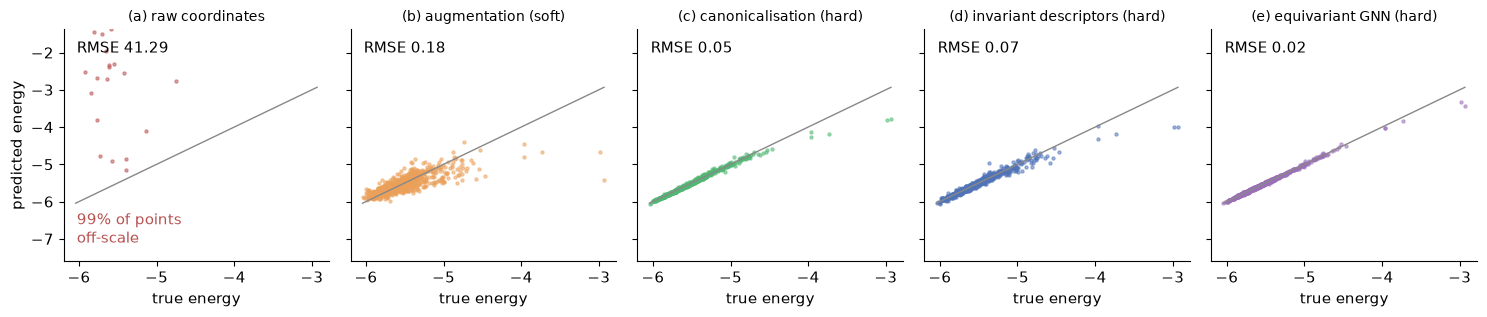

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.3), sharex=True, sharey=True)
lo, hi = E_test.min().item(), E_test.max().item()
for ax, k in zip(axes, "abcde"):
    ax.plot([lo, hi], [lo, hi], color=GREY, lw=1)
    ax.scatter(E_test, preds[k], s=5, alpha=0.5, color=COLORS[k])
    ax.set_title(LABELS[k], fontsize=10)
    ax.text(0.05, 0.9, f"RMSE {rmse(preds[k], E_test):.2f}", transform=ax.transAxes)
    if k == "a":
        frac = ((preds[k] - E_test).abs() > hi - lo).float().mean().item()
        ax.text(0.05, 0.08, f"{100 * frac:.0f}% of points\noff-scale", transform=ax.transAxes, color=RED)
    ax.set_xlabel("true energy")
axes[0].set_ylabel("predicted energy")
axes[0].set_ylim(lo - 0.5 * (hi - lo), hi + 0.5 * (hi - lo))
fig.tight_layout()
fig.savefig("figures/fig_II_parity.pdf")
plt.show()

## Test 2: data efficiency

Test 1 was unfair to (a): it had never seen a rotated cluster. Now the training data
come in **random orientations** (the realistic case), and we vary the
number of training configurations from 30 to 3000. Each model is retrained for every
size and evaluated on the rotated test set. This is a **learning curve**: test error
against amount of data, in log-log scale.

What the figure shows:

- **(a)** barely improves, from 0.45 to 0.27: 3000 configurations are too few to cover
  all orientations. The spread of the energies themselves is 0.29, so most of this
  curve is no better than a constant prediction.
- **(b)** does better, about 0.2 from 300 configurations on, and then stops improving:
  its limit is the training needed to learn the rotations, not the amount of data.
- **(c)** keeps improving, down to 0.04: once the pose is standardised, the problem is as
  easy as in a single orientation.
- **(d)** is the best with very little data (0.18 with 30 configurations), then
  **plateaus** near 0.1 and is overtaken by (c). More data do not help: the limit is the
  information lost in the descriptors, not the amount of data.
- **(e)** is the best at every size: 0.07 with 30 configurations, 0.02 with 3000. It is
  invariant like (d), but it learns its own functions of distances and angles instead of
  using fixed ones, so it does not plateau at the same level.

30 {'a': 0.452, 'b': 0.317, 'c': 0.331, 'd': 0.182, 'e': 0.066}


100 {'a': 0.435, 'b': 0.25, 'c': 0.167, 'd': 0.118, 'e': 0.037}


300 {'a': 0.405, 'b': 0.201, 'c': 0.076, 'd': 0.109, 'e': 0.028}


1000 {'a': 0.302, 'b': 0.214, 'c': 0.051, 'd': 0.108, 'e': 0.028}


3000 {'a': 0.272, 'b': 0.222, 'c': 0.038, 'd': 0.105, 'e': 0.023}


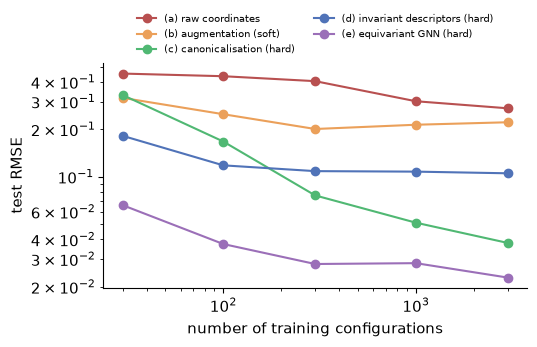

In [11]:
X_pool_rot = rotate(X_pool, torch.Generator().manual_seed(7))
sizes = [30, 100, 300, 1000, 3000]
curves = {k: [] for k in "abcde"}
for n in sizes:
    for k in "abcde":
        m = train(k, X_pool_rot[:n], E_pool[:n], steps=1500)
        curves[k].append(rmse(predict(m, X_test), E_test))
    print(n, {k: round(v[-1], 3) for k, v in curves.items()})

fig, ax = plt.subplots(figsize=(5.5, 3.6))
for k in "abcde":
    ax.loglog(sizes, curves[k], "o-", color=COLORS[k], label=LABELS[k])
ax.set_xlabel("number of training configurations")
ax.set_ylabel("test RMSE")
ax.legend(frameon=False, fontsize=7, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
fig.savefig("figures/fig_II_learning_curve.pdf")
plt.show()

## Test 3: the weak spot of canonicalisation

So far (c) looks like the winner. Here is its price. Take the reference cluster and
move **one atom** smoothly along the sorting direction, until it overtakes its neighbour
in the sorting order. The cell finds the two atoms that are closest in that order and
builds this path of 200 configurations.

Physically nothing special happens: the true energy (grey) changes smoothly. But at the
crossing, the canonical ordering of the atoms changes, so the input vector of model (c)
**jumps** to a region of input space it has never seen. Its prediction jumps from about
$-6$ to $+9$. The model is exactly invariant and **discontinuous**: unusable for forces
or for molecular dynamics, where atoms cross such boundaries all the time.

Models (d) and (e) are built from smooth functions of the positions and follow the true
energy along the whole path.

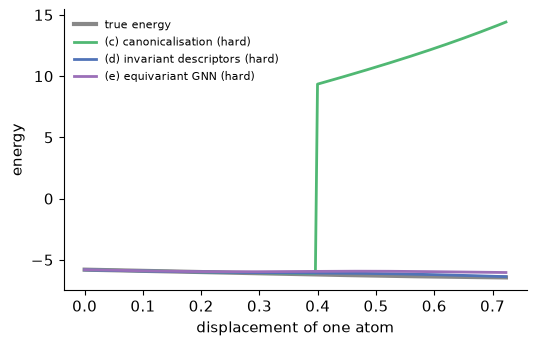

In [12]:
Yref = canonicalise(X_ref[None])[0]
proj = Yref @ U_SORT
order = torch.argsort(proj)
gaps = torch.diff(proj[order])
a = int(torch.argmin(gaps))
i_lo, i_hi = order[a], order[a + 1]          # canonical indices of the closest pair
# direction U_SORT expressed in the original frame
Xc = X_ref - X_ref.mean(0)
_, vecs = torch.linalg.eigh(Xc.T @ Xc)
sign = torch.sign(((Xc @ vecs) ** 3).sum(0))
u_world = vecs @ (sign * U_SORT)
# find which original atom is canonical atom i_lo: match positions
can_pos = Yref[i_lo]
orig = int(torch.argmin(((Xc @ vecs) * sign - can_pos).norm(dim=1)))
s = torch.linspace(0, 2.2 * gaps[a].item(), 200)
X_path = X_ref[None].repeat(len(s), 1, 1)
X_path[:, orig] += s[:, None] * u_world
E_path = energy(X_path)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(s, E_path, color=GREY, lw=3, label="true energy")
for k in "cde":
    ax.plot(s, predict(models[k], X_path), color=COLORS[k], lw=2, label=LABELS[k])
ax.set_xlabel("displacement of one atom")
ax.set_ylabel("energy")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/fig_II_canon_path.pdf")
plt.show()

## Bonus: forces as $F=-\nabla E_\theta$

With model (d), forces come from automatic differentiation of the energy:
they are conservative **by construction** (a hard constraint that is not a symmetry).
The model was trained on energies only; the cell compares its forces with the true ones
on 200 test configurations. The error (about 0.7) is to be compared with the typical size
of a force component (about 2.7): a rough but real prediction of a quantity the model
was never shown. In practice one trains on energies **and** forces.

In [13]:
Xf = X_test[:200].clone().requires_grad_(True)
(F_true,) = torch.autograd.grad(-energy(Xf).sum(), Xf)
Xg = X_test[:200].clone().requires_grad_(True)
(F_pred,) = torch.autograd.grad(-models["d"](Xg).sum(), Xg)
print(f"force RMSE of model (d), never trained on forces: {rmse(F_pred, F_true):.2f} "
      f"(force scale {F_true.std():.2f})")

print(f"total runtime: {time.time() - t_start:.0f} s")

force RMSE of model (d), never trained on forces: 0.70 (force scale 2.73)
total runtime: 186 s


## Take-home messages

- A model that ignores a symmetry must learn it from data, and that is expensive.
- Augmentation is a **soft** constraint: it works, approximately, and it costs accuracy
  and training time. Each symmetry has to be paid for separately, and a large group (720
  relabellings) is out of reach.
- **Hard** constraints hold exactly, for free, and give large gains in data efficiency.
- No route is free: canonicalisation is discontinuous at ambiguous configurations,
  invariant descriptors lose information. The **equivariant** network (e) avoids both and
  is the most accurate here; its price is the computational cost.

## Things to try

1. Change the training budget of the augmented model (`AUG_FACTOR` = 1, then 30). How
   does its error move? Then augment the relabellings too (`rotate_permute` in `train`).
2. Increase the thermal noise (`sigma=0.03` in `sample`) to `0.1`. Which model suffers
   most, and why? (Think of the ambiguous configurations of the canonical pose.)
3. Remove the angular descriptors: return only `g_rad` in `descriptors` and set
   `N_DESC = 12`. How does the plateau of (d) move in Test 2?
4. In Test 1, compare `predict(models["a"], X_test0)` with the prediction on the same
   configurations merely **translated** by a constant vector.